In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

#### Residual Network Background

The fundamental premise of Residual Networks (ResNets) is the mitigation of the **degradation problem** in ultra-deep neural networks. As traditional convolutional networks grow deeper (e.g., stacking 50 or 100 layers), their training error paradoxically increases. This is not caused by overfitting, but rather because standard optimization algorithms struggle to navigate the exponentially complex hypothesis space, making it nearly impossible for deep layers to learn even simple identity mappings.

ResNets solve this by fundamentally altering the mathematical mapping of the layers using **skip connections** (or shortcut connections).


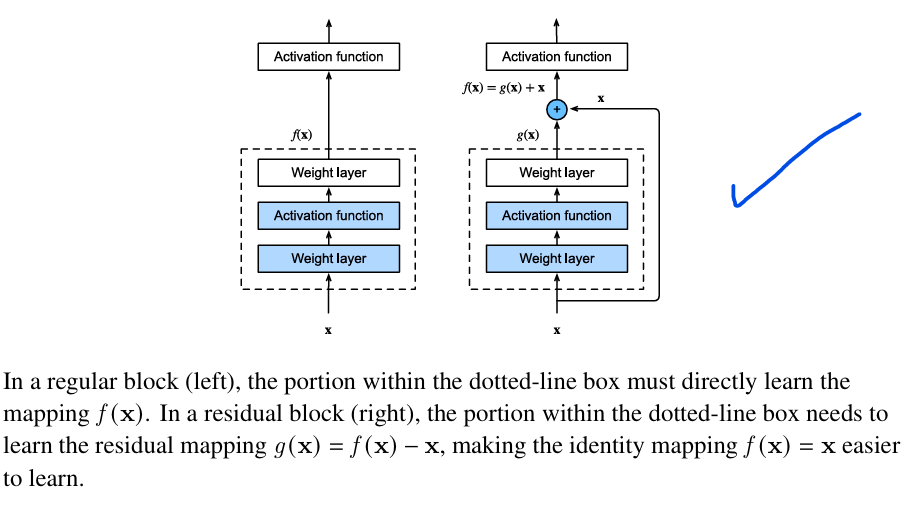

### 1. The Mathematics of the Forward Pass

In a standard feed-forward network, we stack non-linear layers and hope they directly approximate a complex underlying target function, which we will call $\mathcal{H}(x)$.

The ResNet architecture argues that it is excessively difficult for a stack of non-linear layers to learn the exact identity mapping ($\mathcal{H}(x) = x$). Therefore, instead of forcing the layers to learn the complete transformation $\mathcal{H}(x)$, we force them to learn the **residual mapping**, denoted as $\mathcal{F}(x)$.

We redefine our target function as:


$$\mathcal{H}(x) = \mathcal{F}(x) + x$$

Rearranging this, the layers are now only responsible for learning the difference (the residual) between the input and the output:


$$\mathcal{F}(x) = \mathcal{H}(x) - x$$

In code and architecture, this is implemented by taking the input $x$, passing it through a few convolutional layers to compute $\mathcal{F}(x)$, and then performing an element-wise addition with the original input $x$ before the final ReLU activation:


$$y = \text{ReLU}(\mathcal{F}(x, \{W_i\}) + x)$$

### 2. The Function Class Perspective (Theoretical Guarantee)

Relating this back to our discussion on function classes, ResNets provide a strict mathematical guarantee regarding capacity.

If you add a new block of layers to a standard CNN, you fundamentally alter the hypothesis space. There is no guarantee the new space contains the optimal function found by the shallower network.

However, in a ResNet, the new, deeper function class strictly subsumes the shallower one. If the optimal mapping for a layer is simply the identity function (meaning no further transformations are needed), the solver simply drives the weights of $\mathcal{F}(x)$ to zero.
If $\mathcal{F}(x) = 0$, then $\mathcal{H}(x) = 0 + x = x$.
Because it is trivially easy for neural networks to push weights to zero via L2 regularization (Weight Decay), deeper ResNets are mathematically guaranteed to perform at least as well as their shallower counterparts.

### 3. The Mathematics of Backpropagation (The True Power)

The true brilliance of ResNets is revealed during backpropagation. To see why they completely eliminate the vanishing gradient problem, we can unroll the recursive formula of a residual block.

Let $x_l$ be the input to the $l$-th residual block, and $x_{l+1}$ be its output:


$$x_{l+1} = x_l + \mathcal{F}(x_l, \mathcal{W}_l)$$

If we apply this recursively from a shallow layer $l$ to a much deeper layer $L$, we get:


$$x_L = x_l + \sum_{i=l}^{L-1} \mathcal{F}(x_i, \mathcal{W}_i)$$

This equation shows that the feature $x_L$ of any deep layer is the exact feature of a shallow layer $x_l$ plus the sum of all the residuals in between.

Now, let $\mathcal{E}$ be the loss function. Using the chain rule, the gradient of the loss with respect to the shallow layer $x_l$ is:


$$\frac{\partial \mathcal{E}}{\partial x_l} = \frac{\partial \mathcal{E}}{\partial x_L} \frac{\partial x_L}{\partial x_l}$$

Substituting our recursive equation into the derivative yields the definitive ResNet gradient equation:


$$\frac{\partial \mathcal{E}}{\partial x_l} = \frac{\partial \mathcal{E}}{\partial x_L} \left( 1 + \frac{\partial}{\partial x_l} \sum_{i=l}^{L-1} \mathcal{F}(x_i, \mathcal{W}_i) \right)$$

This equation is why ResNets can be trained to depths of 1,000 layers or more:

* **The Unhindered Path (The "$1$"):** The scalar $1$ propagates the gradient $\frac{\partial \mathcal{E}}{\partial x_L}$ directly back to any shallow layer $l$ without any weight matrices multiplying it, meaning the gradient literally cannot vanish.
* **The Residual Path:** The summation term routes the gradients through the weight matrices to actually update the parameters. Even if this entire summation term evaluates to $0$ (which causes the vanishing gradient in standard networks), the $1$ guarantees the error signal survives to the beginning of the network.

### 4. The Bottleneck Architecture

Similar to GoogLeNet's Inception module, ultra-deep ResNets (like ResNet-50, ResNet-101) use a **Bottleneck Block** to maintain computational feasibility.
Instead of two $3 \times 3$ convolutions, a bottleneck block uses three layers:

1. A $1 \times 1$ convolution to reduce the channel dimensions (the bottleneck).
2. A $3 \times 3$ convolution applied to the compressed dimensions.
3. A $1 \times 1$ convolution to restore the channel dimensions back to their original size so the skip connection addition ($+ x$) aligns perfectly.


### Forward and Backward pass in ResNet

# Forward Propagation

If the output of the $\ell$-th residual block is the input to the $(\ell+1)$-th residual block (assuming no activation function between blocks), then the $(\ell+1)$-th input is:

$$
x_{\ell+1} = F(x_\ell) + x_\ell
$$

Applying this formulation recursively, we obtain:

$$
\begin{aligned}
x_{\ell+2} &= F(x_{\ell+1}) + x_{\ell+1} \\
&= F(x_{\ell+1}) + F(x_\ell) + x_\ell
\end{aligned}
$$

This yields the general relationship:

$$
\boxed{
x_L = x_\ell + \sum_{i=\ell}^{L-1} F(x_i)
}
$$

where $L$ is the index of a residual block and $\ell$ is the index of some earlier block. This formulation suggests that there is always a signal that is directly sent from a shallower block $\ell$ to a deeper block $L$.

# Backward Propagation

The residual learning formulation provides the added benefit of mitigating the vanishing gradient problem to some extent. However, it is crucial to acknowledge that the vanishing gradient issue is not the root cause of the degradation problem, which is tackled through the use of normalization.

To observe the effect of residual blocks on backpropagation, consider the partial derivative of a loss function $\mathcal{E}$ with respect to some residual block input $x_\ell$.

Using the equation derived above for forward propagation, for a later residual block $L > \ell$, we obtain:

$$
\begin{aligned}
\frac{\partial \mathcal{E}}{\partial x_\ell}
&= \frac{\partial \mathcal{E}}{\partial x_L}
\frac{\partial x_L}{\partial x_\ell} \\[8pt]
&= \frac{\partial \mathcal{E}}{\partial x_L}
\left(
1 + \frac{\partial}{\partial x_\ell}
\sum_{i=\ell}^{L-1} F(x_i)
\right) \\[8pt]
&= \frac{\partial \mathcal{E}}{\partial x_L}
+ \frac{\partial \mathcal{E}}{\partial x_L}
\frac{\partial}{\partial x_\ell}
\sum_{i=\ell}^{L-1} F(x_i)
\end{aligned}
$$

This formulation suggests that the gradient computation of a shallower layer,

$$
\frac{\partial \mathcal{E}}{\partial x_\ell},
$$

always contains a later term,

$$
\frac{\partial \mathcal{E}}{\partial x_L},
$$

that is directly added.

Even if the gradients of the $F(x_i)$ terms are small, the total gradient

$$
\frac{\partial \mathcal{E}}{\partial x_\ell}
$$

resists vanishing due to the added term

$$
\frac{\partial \mathcal{E}}{\partial x_L}.
$$

In [2]:
class Residual(nn.Module):
    def __init__(self, num_channels, use_1x1conv=False, strides=1):
        super().__init__()

        self.conv1 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1, stride=strides)
        self.conv2 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1)

        if use_1x1conv:
            self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1, stride=strides)
        else: 
            self.conv3 = None

        self.bn1 = nn.LazyBatchNorm2d()
        self.bn2 = nn.LazyBatchNorm2d()

    def forward(self, X):
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = self.bn2(self.conv2(Y))
        if self.conv3 is not None:
            X = self.conv3(X)
        Y += X
        return F.relu(Y)

In [4]:
blk = Residual(3)
X = torch.randn(4, 3, 6, 6)
blk(X).shape

torch.Size([4, 3, 6, 6])

In [5]:
X = torch.randn(4, 3, 6, 6)
blk = Residual(6, use_1x1conv=True, strides=2)
blk(X).shape

torch.Size([4, 6, 3, 3])

### ResNet-18 Architecture

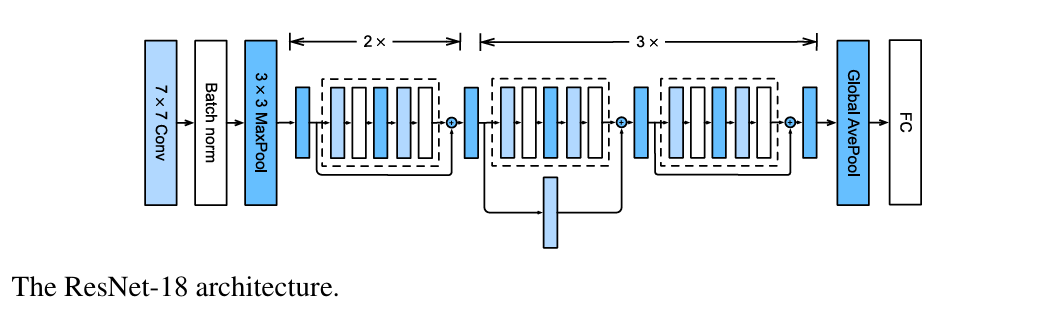

ResNet-18 is the lightest standardized variant of the Residual Network family. It achieves its depth without excessive computational overhead by stacking "Basic Blocks" rather than the more complex "Bottleneck Blocks" used in its deeper siblings (like ResNet-50).

The architecture takes a standard $224 \times 224$ RGB image and processes it through five distinct stages, totaling exactly 18 layers with learnable weights (17 convolutional layers and 1 fully connected layer).

### 1. The Stem (Initial Convolution)

Before entering the residual blocks, the network aggressively downsamples the input to reduce computational load.

* **Conv1:** A large $7 \times 7$ convolution with 64 filters and a stride of 2, followed by Batch Normalization and a ReLU activation.
* **Pooling:** A $3 \times 3$ Max Pooling layer with a stride of 2.
* **Output:** The spatial dimensions are rapidly compressed by a factor of 4, leaving a $56 \times 56$ feature map with 64 channels.

### 2. The Residual Stages (Layers 1-4)

The core of the network consists of four sequential stages. Each stage contains exactly two **Basic Blocks**. A Basic Block consists of two consecutive $3 \times 3$ convolutional layers (each followed by Batch Norm and ReLU) with a skip connection wrapping around them.

* **Stage 1 (Conv2_x):** Contains 2 blocks (4 total convolutions). It uses 64 filters. Because it matches the stem's output, no spatial downsampling occurs. Output remains $56 \times 56 \times 64$.
* **Stage 2 (Conv3_x):** Contains 2 blocks (4 total convolutions). The number of filters doubles to 128. The very first convolution in this stage uses a stride of 2, halving the spatial dimensions. Output is $28 \times 28 \times 128$.
* **Stage 3 (Conv4_x):** Contains 2 blocks (4 total convolutions). Filters double to 256. The first convolution uses a stride of 2. Output is $14 \times 14 \times 256$.
* **Stage 4 (Conv5_x):** Contains 2 blocks (4 total convolutions). Filters double to 512. The first convolution uses a stride of 2. Output is $7 \times 7 \times 512$.


Below is the structure of residual block. It consist of 2 convolutional layers and a skip connection. Batch Normalization is used between
the convolutional layers and ReLU is used as the activation function.
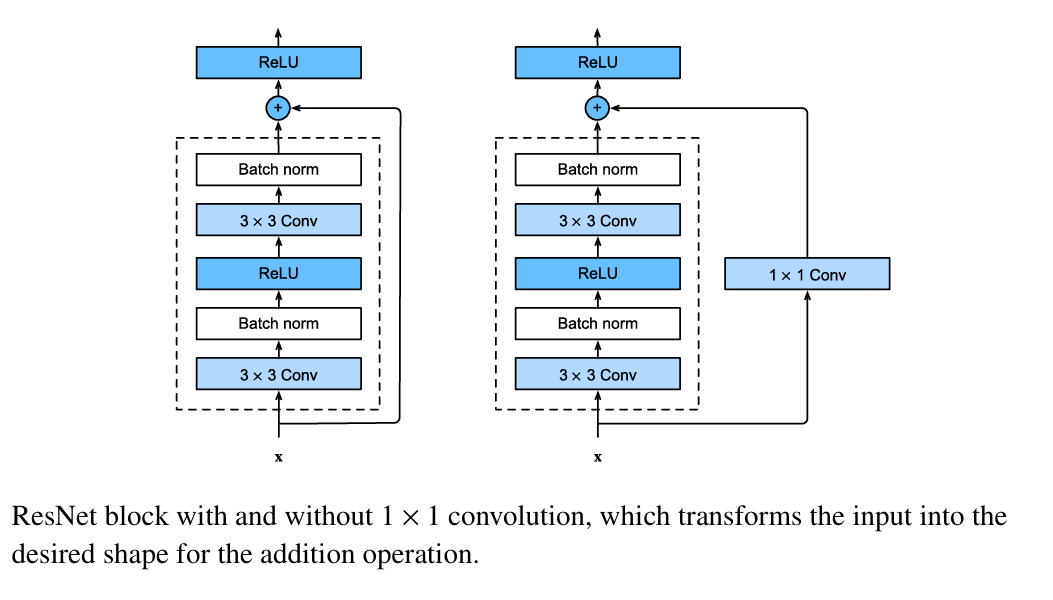


### 3. The Classification Head

Borrowing the philosophy from the "Network in Network" architecture, ResNet-18 discards heavy, memory-intensive fully connected layers.

* **Global Average Pooling (GAP):** A pooling layer averages the final $7 \times 7$ spatial grid into a single $1 \times 1$ pixel, resulting in a flat 512-dimensional vector.
* **Fully Connected (FC) Layer:** A single linear layer maps the 512-dimensional vector to the final target classes (e.g., 1000 logits for ImageNet).

**Counting the Layers:** 1 (Stem) + 16 (4 stages $\times$ 4 convolutions) + 1 (FC Classification Head) = **18 layers**.


### **Using 1x1 convolutional layer for linear projection of input x**

When the main convolutional branch $\mathcal{F}(x)$ halves the spatial resolution (e.g., $56 \times 56 \rightarrow 28 \times 28$) and doubles the channel depth (e.g., $64 \rightarrow 128$), the original input $x$ cannot be added directly due to the tensor shape mismatch.

To resolve this, a **Projection Shortcut** is applied directly to the skip connection. The input $x$ is routed through a $1 \times 1$ convolutional layer configured with a stride of 2 and the new target number of filters.

* **Spatial Alignment:** The stride of 2 forces the convolution to skip pixels, mathematically shrinking the spatial grid to perfectly match the downsampled main branch.
* **Depth Alignment:** The increased number of filters projects the original channels into the new, expanded dimensional space.

The transformed $x$ now matches the exact shape of $\mathcal{F}(x)$, allowing the element-wise addition to compute. Your conclusion that a $1 \times 1$ convolution is used to align the dimensions is entirely accurate.

Would you like to examine how ResNeXt evolves this architecture by splitting the main branch into dozens of parallel $1 \times 1$ pathways (cardinality) to increase accuracy without increasing parameter count?




In [3]:
class ResNet(d2l.Classifier):

    def __init__(self, arch, lr=0.1, num_classes=10):
        super(ResNet, self).__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(self.b1())

        for i, module in enumerate(arch):
            self.net.add_module(f'b{i+2}', self.block(*module, first_block=(i==0)))
        
        self.net.add_module('last', nn.Sequential(
        nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
        nn.LazyLinear(num_classes)))
        self.net.apply(d2l.init_cnn)
    


    def b1(self):
        return nn.Sequential(
            nn.LazyConv2d(out_channels=64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
    
    def block(self, num_residuals, num_channels, first_block=False):
        blk = []

        for i in range(num_residuals):
            if i==0 and not first_block:
                blk.append(Residual(num_channels, use_1x1conv=True, strides=2))
            else:
                blk.append(Residual(num_channels))
        return nn.Sequential(*blk)


In [14]:
class ResNet18(ResNet):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__(
            arch=[
                (2, 64),
                (2, 128),
                (2, 256),
                (2, 512)
            ],
            lr=lr,
            num_classes=num_classes
        )

In [15]:
ResNet18().layer_summary((1, 1, 96, 96))

Sequential output shape:	 torch.Size([1, 64, 24, 24])
Sequential output shape:	 torch.Size([1, 64, 24, 24])
Sequential output shape:	 torch.Size([1, 128, 12, 12])
Sequential output shape:	 torch.Size([1, 256, 6, 6])
Sequential output shape:	 torch.Size([1, 512, 3, 3])
Sequential output shape:	 torch.Size([1, 10])


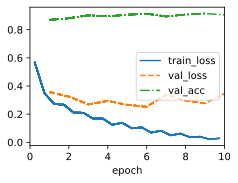

In [16]:
model = ResNet18(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
model.apply_init([next(iter(data.get_dataloader(True)))[0]], d2l.init_cnn)
trainer.fit(model, data)

### Training result
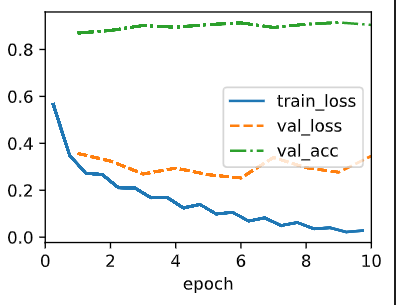

### ResNeXt Architecture

Below is the structure of ResNeXt block

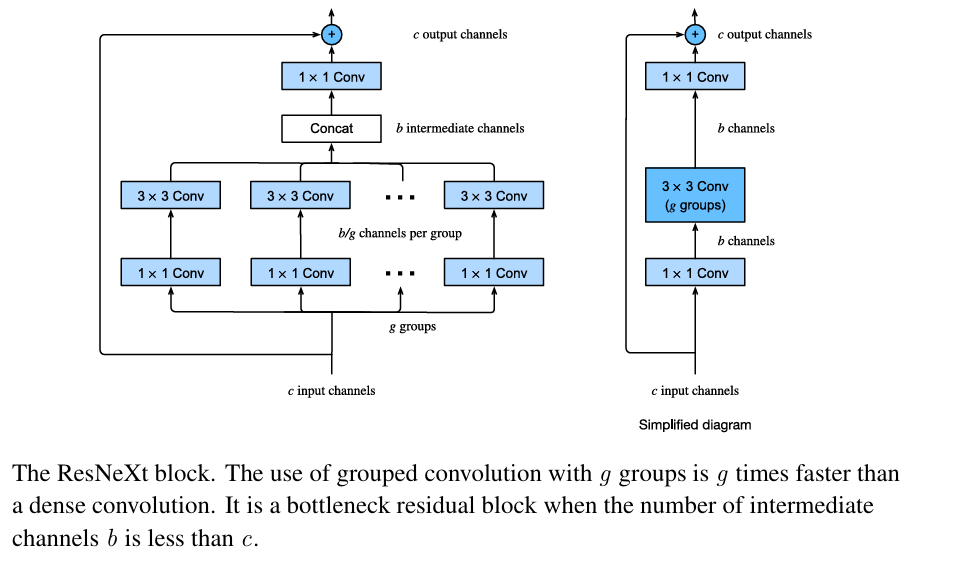

ResNeXt is the elegant mathematical synthesis of the two architectures we just discussed: the residual mapping of ResNet and the parallel branching of GoogLeNet (Inception).

While traditional networks scaled up by increasing **Depth** (adding more layers) or **Width** (adding more filters per layer), ResNeXt introduced a third, highly effective dimension for scaling neural capacity: **Cardinality**.

Here is the structural and mathematical breakdown of how ResNeXt evolves the standard residual block.

### 1. The Core Philosophy: "Split-Transform-Merge"

GoogLeNet proved that splitting an input tensor into parallel branches (the Inception module) extracts richer features than a single massive convolution. However, Inception modules are notoriously difficult to design; the architect has to manually guess how many $1 \times 1$, $3 \times 3$, or $5 \times 5$ filters to use in each branch, leading to messy, customized blocks.

ResNeXt borrows this "Split-Transform-Merge" paradigm but enforces strict uniformity. Instead of parallel branches doing different things, a ResNeXt block splits the input into dozens of identical, parallel pathways.

Mathematically, if $C$ is the Cardinality (the number of parallel paths), the residual function $\mathcal{F}(x)$ is redefined as the sum of $C$ identical transformations ($\mathcal{T}_i$):


$$y = x + \sum_{i=1}^{C} \mathcal{T}_i(x)$$

### 2. The Mechanics of a ResNeXt Block

Let's look at a standard ResNeXt block with a Cardinality of 32 ($C=32$). Instead of one massive bottleneck, the block orchestrates 32 tiny bottlenecks working simultaneously.

1. **The Split (Compression):** The input tensor is passed into a $1 \times 1$ convolution to reduce the channel depth. The channels are then mathematically sliced into 32 distinct groups.
2. **The Transform (Parallel Processing):** Each of the 32 groups is passed through its own dedicated $3 \times 3$ convolution. Because each path operates on a tiny fraction of the total channels, the computational cost plummets. Each path learns a highly specialized feature representation independently of the others.
3. **The Merge (Concatenation):** The outputs of all 32 spatial transformations are concatenated back together along the channel dimension.
4. **The Expansion & Addition:** A final $1 \times 1$ convolution projects the merged tensor back to the original large channel depth, and exactly like a standard ResNet, it is added to the original input $x$ via the skip connection.

### 3. The Grouped Convolution Trick (Hardware Efficiency)

Writing PyTorch code to manually slice a tensor 32 times, run 32 separate `nn.Conv2d` operations, and concatenate them back together would be a nightmare for GPU memory and memory bandwidth.

To solve this, ResNeXt relies on **Grouped Convolutions**—a hardware-level optimization originally invented in 2012 for AlexNet (to split the network across two weak GPUs).

In modern frameworks, this entire massive parallel branching architecture is executed in a single line of code by utilizing the `groups` parameter. If you want a 256-channel convolution split into 32 parallel paths, you simply write:
`nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, groups=32)`

The GPU handles the slicing, the parallel $3 \times 3$ matrix multiplications, and the merging completely under the hood, maximizing CUDA core utilization.

### 4. Why Cardinality Wins

The empirical results of the ResNeXt paper proved a fundamental rule about function classes in deep learning: **Increasing cardinality is strictly more effective than increasing depth or width.**

If you have a strict computational budget of 25 million parameters, a ResNeXt model with high cardinality (e.g., $32 \times 4d$) will consistently achieve lower validation error than a standard ResNet of the exact same parameter count. By forcing the network to learn 32 distinct, independent spatial transformations per block, you artificially inflate the representational capacity of the function class without actually adding more weights to the mathematical equation.


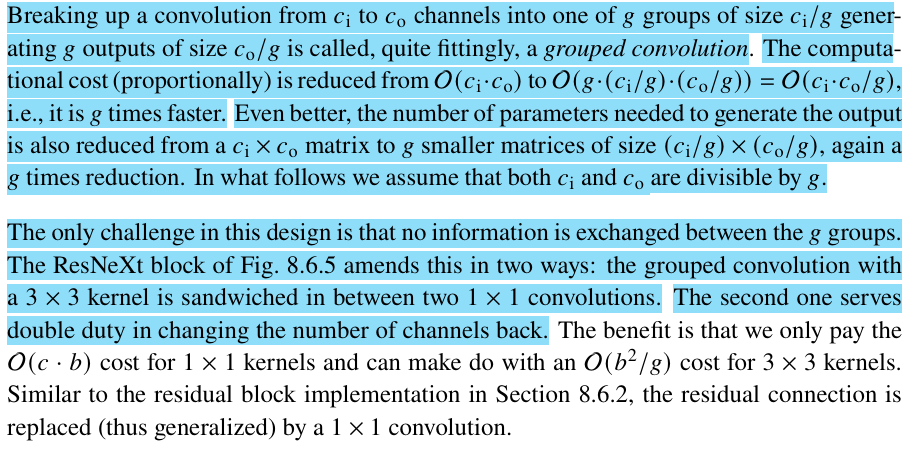


In [4]:
class ResNeXtBlock(nn.Module):
    def __init__(self, num_channels, groups, bot_mul, use_1x1conv=False, strides=1):
        super().__init__()
        bot_channels = int(round(num_channels * bot_mul))
        self.conv1 = nn.LazyConv2d(bot_channels, kernel_size=1, stride=1)
        self.conv2 = nn.LazyConv2d(bot_channels, kernel_size=3, stride=strides, padding=1, groups=bot_channels//groups)
        self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1, stride=1)

        self.bn1 = nn.LazyBatchNorm2d()
        self.bn2 = nn.LazyBatchNorm2d()
        self.bn3 = nn.LazyBatchNorm2d()

        if use_1x1conv:
            self.conv4 = nn.LazyConv2d(bot_channels, kernel_size=1, stride=strides)
            self.bn4 = nn.LazyBatchNorm2d()
        else:
            self.conv4 = None
            self.bn4 = None

    def forward(self, X):
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = F.relu(self.bn2(self.conv2(Y)))
        Y = self.bn3(self.conv3(Y))
        if self.conv4 is not None:
            X = self.conv4(X)
            X = self.bn4(X)
        Y += X
        return F.relu(Y)



In [5]:
blk = ResNeXtBlock(32, 16, 1)
X = torch.randn(4, 32, 96, 96)
blk(X).shape

torch.Size([4, 32, 96, 96])

### Different variants of ResNet introduced in original paper

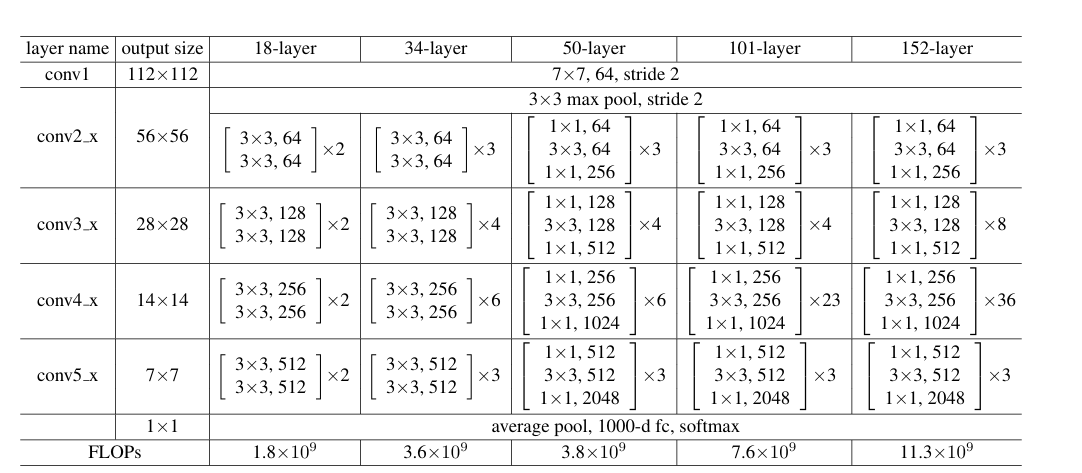

The **STEM** and **HEAD** are the same for all ResNet variants. The **BODY** is the only difference.


In [7]:
class ResNet34(ResNet):
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__(
            arch=[
                (3, 64),
                (4, 128),
                (6, 256),
                (3, 512)
            ],
            lr=lr,
            num_classes=num_classes
        )

### Bottlenet Architecture 

For deeper networks, ResNet introduces a “bottleneck” architecture to reduce model complexity.

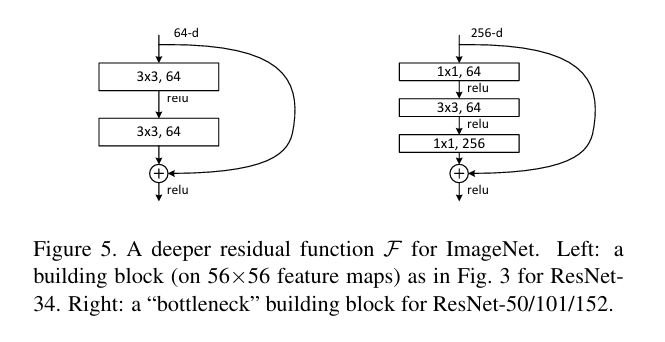


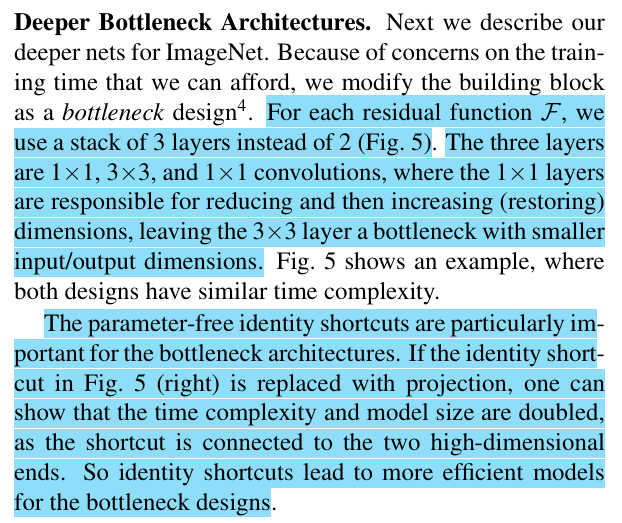

In [8]:
class Bottleneck(nn.Module):
    # The expansion factor dictates how much the final 1x1 conv expands the channels
    expansion = 4

    def __init__(self, in_channels, out_channels, stride=1):
        super(Bottleneck, self).__init__()
        
        # 1x1 Conv: Reduce dimensions
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        
        # 3x3 Conv: The bottleneck layer
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, 
                               stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        # 1x1 Conv: Restore (expand) dimensions
        self.conv3 = nn.Conv2d(out_channels, out_channels * self.expansion, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_channels * self.expansion)
        
        self.relu = nn.ReLU(inplace=True)
        
        # Shortcut connection
        self.shortcut = nn.Sequential()
        # Use a 1x1 projection if dimensions or stride change so the addition works
        if stride != 1 or in_channels != out_channels * self.expansion:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels * self.expansion, kernel_size=1, 
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels * self.expansion)
            )

    def forward(self, x):
        identity = self.shortcut(x)
        
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)
        
        out = self.conv3(out)
        out = self.bn3(out)
        
        # F(x) + x
        out += identity
        out = self.relu(out)
        
        return out